In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

data_path = "data"

In [6]:
images = []
labels = []

for subject in range(1, 41):
    folder = os.path.join(data_path, f"s{subject}")
    files = sorted(os.listdir(folder))
    for f in files:
        img = Image.open(os.path.join(folder, f))
        images.append(np.array(img))
        labels.append(subject)

images = np.array(images)
labels = np.array(labels)

Images array shape: (400, 112, 92)
Single image shape: (112, 92)
Data type: uint8
Min / Max pixel value: 0 251


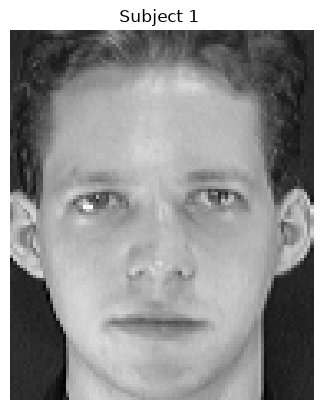

In [9]:
print("Images array shape:", images.shape)
print("Single image shape:", images[0].shape)
print("Data type:", images.dtype)
print("Min / Max pixel value:", images.min(), images.max())

plt.imshow(images[0], cmap="gray")
plt.title(f"Subject {labels[0]} ")
plt.axis("off")
plt.show()

In [13]:
n_samples, h, w = images.shape
X = images.reshape(n_samples, h * w).astype(np.float64)
y = labels

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (400, 10304)
y shape: (400,)


In [14]:
rng = np.random.default_rng(42)

train_idx, test_idx = [], []
for subject in np.unique(y):
    idx = np.where(y == subject)[0]
    rng.shuffle(idx)
    train_idx.extend(idx[:8])
    test_idx.extend(idx[8:])

train_idx = np.array(train_idx)
test_idx = np.array(test_idx)

X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

print("Train:", X_train.shape)
print("Test: ", X_test.shape)

assert len(set(train_idx) & set(test_idx)) == 0
assert set(y_train) == set(y_test) == set(range(1, 41))
print("All checks passed.")

Train: (320, 10304)
Test:  (80, 10304)
All checks passed.


mean_face shape: (10304,)
X_centered shape: (320, 10304)


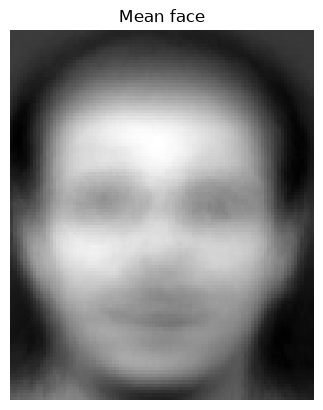

In [15]:
mean_face = X_train.mean(axis=0)
X_centered = X_train - mean_face

print("mean_face shape:", mean_face.shape)     
print("X_centered shape:", X_centered.shape)   

plt.imshow(mean_face.reshape(h, w), cmap="gray")
plt.title("Mean face")
plt.axis("off")
plt.show()

In [16]:
n = X_centered.shape[0]    

U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

eigvals_svd = S**2 / (n - 1)

print("U shape:", U.shape)    
print("S shape:", S.shape)     
print("Vt shape:", Vt.shape)   
print("First 5 eigenvalues:", eigvals_svd[:5])

U shape: (320, 320)
S shape: (320,)
Vt shape: (320, 10304)
First 5 eigenvalues: [2831576.37851826 2087286.66443096 1098443.245922    900197.68600018
  824757.66441736]


In [17]:
# Small covariance matrix (320 x 320) instead of the huge 10304 x 10304 one
C_small = (X_centered @ X_centered.T) / (n - 1)

eigvals, eigvecs_small = np.linalg.eigh(C_small)

# eigh returns ascending order, so reverse to get largest first
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs_small = eigvecs_small[:, order]

# Keep n-1 components (centering makes the last one ~0)
k_max = n - 1
eigvals = eigvals[:k_max]
eigvecs_small = eigvecs_small[:, :k_max]

# Map back to pixel space and normalize each direction to length 1
V_eig = X_centered.T @ eigvecs_small                  # (10304, 319)
V_eig = V_eig / np.linalg.norm(V_eig, axis=0)

print("V_eig shape:", V_eig.shape)
print("First 5 eigenvalues:", eigvals[:5])

V_eig shape: (10304, 319)
First 5 eigenvalues: [2831576.37851826 2087286.66443096 1098443.245922    900197.68600018
  824757.66441736]


In [18]:
# 1. Do the eigenvalues match?
print("Eigenvalues match:", np.allclose(eigvals[:k_max], eigvals_svd[:k_max]))

# 2. Do the directions match? (they can differ by a sign flip)
for i in range(5):
    similarity = abs(np.dot(V_eig[:, i], Vt[i]))
    print(f"Component {i}: |cosine similarity| = {similarity:.6f}")

Eigenvalues match: True
Component 0: |cosine similarity| = 1.000000
Component 1: |cosine similarity| = 1.000000
Component 2: |cosine similarity| = 1.000000
Component 3: |cosine similarity| = 1.000000
Component 4: |cosine similarity| = 1.000000


In [19]:
total_var = eigvals_svd.sum()
explained_ratio = eigvals_svd / total_var
cumulative = np.cumsum(explained_ratio)

print("Variance explained by first 5 components:", explained_ratio[:5])
print("Cumulative after 10 components:", cumulative[9])

Variance explained by first 5 components: [0.1765607  0.13015111 0.06849256 0.05613111 0.05142711]
Cumulative after 10 components: 0.6031374686827039


In [22]:
k = int(np.argmax(cumulative >= 0.90)) + 1
print("Components needed for 90% variance:", k)
print("Actual variance retained:", cumulative[k - 1])
print("Compression: from", h * w, "numbers to", k, "per image")

Components needed for 90% variance: 98
Actual variance retained: 0.9002717598665031
Compression: from 10304 numbers to 98 per image


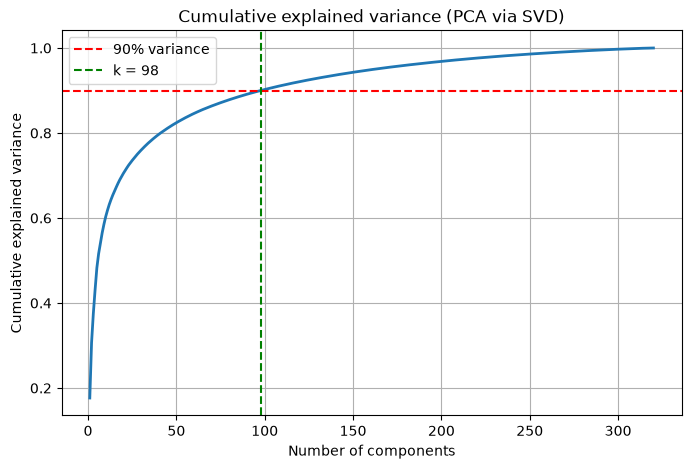

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative) + 1), cumulative, linewidth=2)
plt.axhline(0.90, color="red", linestyle="--", label="90% variance")
plt.axvline(k, color="green", linestyle="--", label=f"k = {k}")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance (PCA via SVD)")
plt.legend()
plt.grid(True)
plt.savefig("explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()

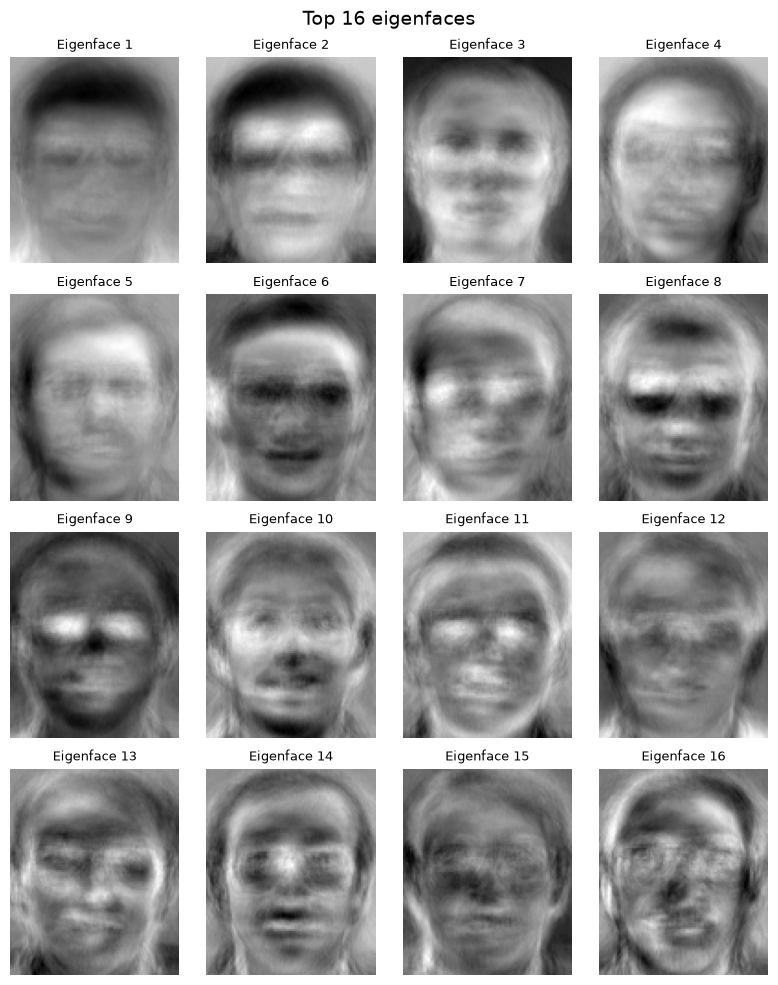

In [24]:
n_show = 16
fig, axes = plt.subplots(4, 4, figsize=(8, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(Vt[i].reshape(h, w), cmap="gray")
    ax.set_title(f"Eigenface {i + 1}", fontsize=9)
    ax.axis("off")

plt.suptitle("Top 16 eigenfaces", fontsize=14)
plt.tight_layout()
plt.savefig("eigenfaces.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
V_k = Vt[:k]                                  

Z_train = X_centered @ V_k.T                   
Z_test  = (X_test - mean_face) @ V_k.T         

print("V_k shape:", V_k.shape)
print("Z_train shape:", Z_train.shape)
print("Z_test shape:", Z_test.shape)

np.save("Z_train.npy", Z_train)
np.save("Z_test.npy", Z_test)
np.save("V_k.npy", V_k)
np.save("mean_face.npy", mean_face)

V_k shape: (98, 10304)
Z_train shape: (320, 98)
Z_test shape: (80, 98)


In [26]:
X_recon_train = Z_train @ V_k + mean_face     

mse = np.mean((X_train - X_recon_train) ** 2)
print("Average reconstruction MSE (train):", mse)
print("Average reconstruction RMSE (pixel levels):", np.sqrt(mse))

Average reconstruction MSE (train): 154.73453255085664
Average reconstruction RMSE (pixel levels): 12.439233599818625


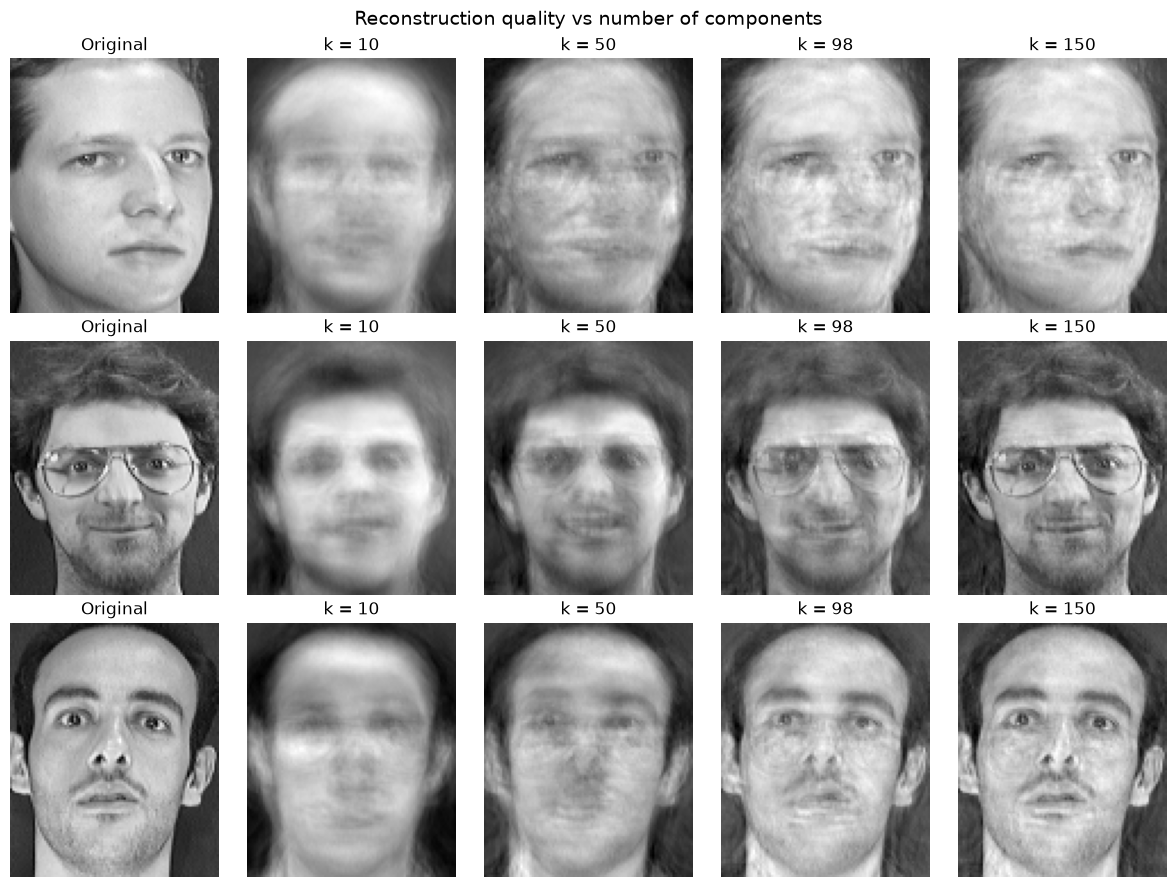

In [27]:
sample_ids = [0, 50, 120]                      # three training faces
k_values = [10, 50, k, 150]

fig, axes = plt.subplots(len(sample_ids), len(k_values) + 1, figsize=(12, 9))

for row, idx in enumerate(sample_ids):
    axes[row, 0].imshow(X_train[idx].reshape(h, w), cmap="gray")
    axes[row, 0].set_title("Original")
    axes[row, 0].axis("off")

    for col, kk in enumerate(k_values, start=1):
        Vkk = Vt[:kk]
        z = (X_train[idx] - mean_face) @ Vkk.T
        recon = z @ Vkk + mean_face
        axes[row, col].imshow(recon.reshape(h, w), cmap="gray")
        axes[row, col].set_title(f"k = {kk}")
        axes[row, col].axis("off")

plt.suptitle("Reconstruction quality vs number of components", fontsize=14)
plt.tight_layout()
plt.savefig("reconstructions.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
n_train = X_train.shape[0]
D = h * w                                      
bytes_per_number = 8                          

orig_numbers = n_train * D
pca_numbers = n_train * k + k * D + D          

orig_mb = orig_numbers * bytes_per_number / 1e6
pca_mb = pca_numbers * bytes_per_number / 1e6

print(f"Original storage : {orig_numbers:,} numbers  ({orig_mb:.2f} MB)")
print(f"PCA storage      : {pca_numbers:,} numbers  ({pca_mb:.2f} MB)")
print(f"Compression ratio: {orig_numbers / pca_numbers:.2f}x")
print(f"Per-image: {D} numbers -> {k} numbers  ({D / k:.1f}x smaller)")

print("\nReconstruction error for different k:")
for kk in [10, 25, 50, k, 100, 150, 200]:
    Vkk = Vt[:kk]
    recon = ((X_train - mean_face) @ Vkk.T) @ Vkk + mean_face
    err = np.mean((X_train - recon) ** 2)
    print(f"k = {kk:3d}   MSE = {err:10.2f}   RMSE = {np.sqrt(err):6.2f}")

Original storage : 3,297,280 numbers  (26.38 MB)
PCA storage      : 1,051,456 numbers  (8.41 MB)
Compression ratio: 3.14x
Per-image: 10304 numbers -> 98 numbers  (105.1x smaller)

Reconstruction error for different k:
k =  10   MSE =     615.76   RMSE =  24.81
k =  25   MSE =     410.47   RMSE =  20.26
k =  50   MSE =     272.75   RMSE =  16.51
k =  98   MSE =     154.73   RMSE =  12.44
k = 100   MSE =     151.48   RMSE =  12.31
k = 150   MSE =      88.65   RMSE =   9.42
k = 200   MSE =      48.85   RMSE =   6.99


In [ ]:
def nearest_neighbor(Z_gallery, Z_query):
   
    d2 = (
        (Z_query ** 2).sum(axis=1)[:, None]
        + (Z_gallery ** 2).sum(axis=1)[None, :]
        - 2 * Z_query @ Z_gallery.T
    )
    d2 = np.maximum(d2, 0)                     
    nn_idx = np.argmin(d2, axis=1)             
    nn_dist = np.sqrt(d2[np.arange(len(Z_query)), nn_idx])
    return nn_idx, nn_dist

In [ ]:
nn_idx, nn_dist = nearest_neighbor(Z_train, Z_test)
y_pred_pca = y_train[nn_idx]                    

correct = (y_pred_pca == y_test)
acc_pca = correct.mean()

print(f"PCA (k = {k}) nearest-neighbor accuracy: {acc_pca * 100:.2f}%")
print(f"Correct: {correct.sum()} / {len(y_test)}")
print(f"Wrong  : {(~correct).sum()}")

PCA (k = 98) nearest-neighbor accuracy: 98.75%
Correct: 79 / 80
Wrong  : 1


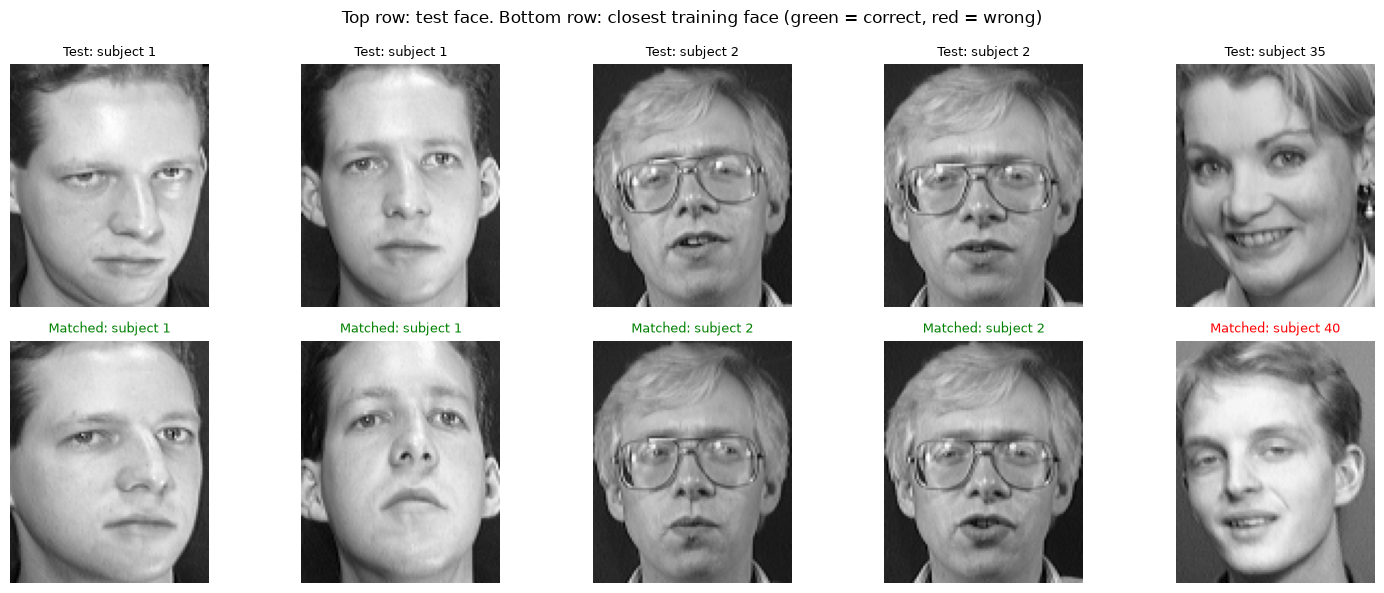

In [31]:
correct_ids = np.where(correct)[0]
wrong_ids = np.where(~correct)[0]

n_show_c = min(4, len(correct_ids))
n_show_w = min(4, len(wrong_ids))

fig, axes = plt.subplots(2, n_show_c + n_show_w, figsize=(3 * (n_show_c + n_show_w), 6), squeeze=False)

def draw(col, test_i, ok):
    train_i = nn_idx[test_i]
    axes[0, col].imshow(X_test[test_i].reshape(h, w), cmap="gray")
    axes[0, col].set_title(f"Test: subject {y_test[test_i]}", fontsize=9)
    axes[1, col].imshow(X_train[train_i].reshape(h, w), cmap="gray")
    color = "green" if ok else "red"
    axes[1, col].set_title(f"Matched: subject {y_train[train_i]}", fontsize=9, color=color)
    axes[0, col].axis("off")
    axes[1, col].axis("off")

for c, test_i in enumerate(correct_ids[:n_show_c]):
    draw(c, test_i, True)
for c, test_i in enumerate(wrong_ids[:n_show_w], start=n_show_c):
    draw(c, test_i, False)

plt.suptitle("Top row: test face. Bottom row: closest training face (green = correct, red = wrong)")
plt.tight_layout()
plt.savefig("matches_pca.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
import time

# Raw pixel matching
t0 = time.perf_counter()
nn_raw, _ = nearest_neighbor(X_train, X_test)
t_raw = time.perf_counter() - t0
acc_raw = (y_train[nn_raw] == y_test).mean()

# PCA matching (matching step only)
t0 = time.perf_counter()
nn_p, _ = nearest_neighbor(Z_train, Z_test)
t_pca = time.perf_counter() - t0

print(f"{'Representation':<18}{'Features':>10}{'Accuracy':>12}{'Match time (s)':>18}")
print(f"{'Raw pixels':<18}{X_train.shape[1]:>10}{acc_raw * 100:>11.2f}%{t_raw:>18.5f}")
print(f"{'PCA (k=' + str(k) + ')':<18}{k:>10}{acc_pca * 100:>11.2f}%{t_pca:>18.5f}")

raw_mb = X_train.nbytes / 1e6
pca_mb_store = Z_train.nbytes / 1e6
print(f"\nStored gallery size: raw = {raw_mb:.2f} MB, PCA = {pca_mb_store:.2f} MB")

Representation      Features    Accuracy    Match time (s)
Raw pixels             10304     100.00%           0.51934
PCA (k=98)                98      98.75%           0.00106

Stored gallery size: raw = 26.38 MB, PCA = 0.25 MB


In [33]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "KNN (n=1)": KNeighborsClassifier(n_neighbors=1),
    "KNN (n=3)": KNeighborsClassifier(n_neighbors=3),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "SVM (linear)": make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
}

print(f"{'Method':<24}{'Test accuracy':>15}")
print(f"{'NN on raw pixels':<24}{acc_raw * 100:>14.2f}%")
print(f"{'NN on PCA (baseline)':<24}{acc_pca * 100:>14.2f}%")

for name, model in models.items():
    model.fit(Z_train, y_train)
    acc = (model.predict(Z_test) == y_test).mean()
    print(f"{name:<24}{acc * 100:>14.2f}%")

Method                    Test accuracy
NN on raw pixels                100.00%
NN on PCA (baseline)             98.75%
KNN (n=1)                        98.75%
KNN (n=3)                        96.25%
Logistic Regression              95.00%
SVM (linear)                     95.00%
SVM (RBF)                        96.25%


    k             KNN (n=1)   Logistic Regression          SVM (linear)
   10                92.81%                90.00%                94.38%
   20                93.75%                94.38%                95.94%
   30                94.69%                94.38%                97.19%
   40                94.06%                96.25%                95.94%
   50                95.62%                96.25%                95.31%
   60                95.00%                94.69%                95.00%
   80                95.31%                94.06%                93.12%
  100                95.31%                90.31%                88.75%
  150                95.31%                85.00%                80.94%


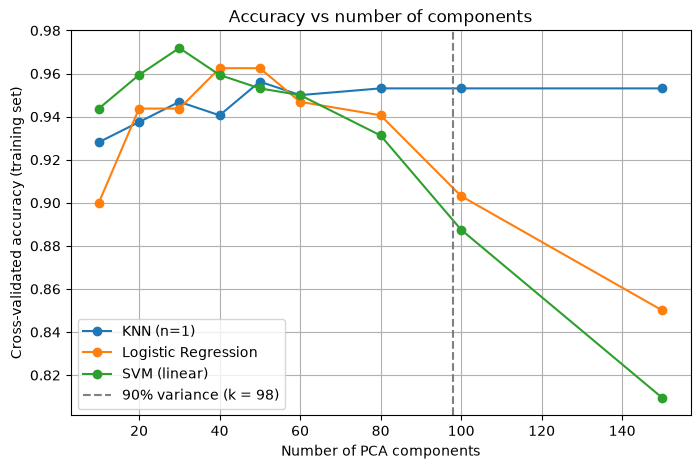

In [34]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Full projection with all components, so we can slice the first kk columns
Z_train_all = X_centered @ Vt.T
Z_test_all = (X_test - mean_face) @ Vt.T

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
k_grid = [10, 20, 30, 40, 50, 60, 80, 100, 150]

cv_models = {
    "KNN (n=1)": KNeighborsClassifier(n_neighbors=1),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "SVM (linear)": make_pipeline(StandardScaler(), SVC(kernel="linear")),
}

cv_scores = {name: [] for name in cv_models}
for kk in k_grid:
    for name, model in cv_models.items():
        s = cross_val_score(model, Z_train_all[:, :kk], y_train, cv=cv).mean()
        cv_scores[name].append(s)

print(f"{'k':>5}" + "".join(f"{n:>22}" for n in cv_models))
for i, kk in enumerate(k_grid):
    print(f"{kk:>5}" + "".join(f"{cv_scores[n][i] * 100:>21.2f}%" for n in cv_models))

plt.figure(figsize=(8, 5))
for name in cv_models:
    plt.plot(k_grid, cv_scores[name], marker="o", label=name)
plt.axvline(k, color="gray", linestyle="--", label=f"90% variance (k = {k})")
plt.xlabel("Number of PCA components")
plt.ylabel("Cross-validated accuracy (training set)")
plt.title("Accuracy vs number of components")
plt.legend()
plt.grid(True)
plt.savefig("accuracy_vs_components.png", dpi=150, bbox_inches="tight")
plt.show()

In [35]:
from sklearn.model_selection import GridSearchCV

# Best k: highest average CV accuracy; ties go to the smaller (more compact) k
mean_cv = np.mean([cv_scores[n] for n in cv_models], axis=0)
best_idx = int(np.argmax(mean_cv))
k_best = k_grid[best_idx]
print("Chosen number of components:", k_best)

Ztr = Z_train_all[:, :k_best]
Zte = Z_test_all[:, :k_best]

grids = {
    "KNN": (KNeighborsClassifier(),
            {"n_neighbors": [1, 3, 5], "weights": ["uniform", "distance"]}),
    "Logistic Regression": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                            {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "SVM": (make_pipeline(StandardScaler(), SVC()),
            {"svc__kernel": ["linear", "rbf"],
             "svc__C": [0.1, 1, 10, 100],
             "svc__gamma": ["scale", 0.001, 0.01]}),
}

best_models = {}
for name, (model, grid) in grids.items():
    gs = GridSearchCV(model, grid, cv=cv)
    gs.fit(Ztr, y_train)
    best_models[name] = gs.best_estimator_
    print(f"{name}: best params = {gs.best_params_}, CV accuracy = {gs.best_score_ * 100:.2f}%")

Chosen number of components: 50
KNN: best params = {'n_neighbors': 1, 'weights': 'uniform'}, CV accuracy = 95.62%
Logistic Regression: best params = {'logisticregression__C': 10}, CV accuracy = 96.56%
SVM: best params = {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}, CV accuracy = 96.88%


In [36]:
import csv

rows = []
rows.append(("NN on raw pixels (baseline)", X_train.shape[1], acc_raw))
rows.append((f"NN on PCA (baseline, k={k})", k, acc_pca))

for name, model in best_models.items():
    acc = (model.predict(Zte) == y_test).mean()
    rows.append((f"{name} (tuned, k={k_best})", k_best, acc))

print(f"{'Method':<36}{'Features':>10}{'Test accuracy':>16}")
for name, feats, acc in rows:
    print(f"{name:<36}{feats:>10}{acc * 100:>15.2f}%")

with open("results_table.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["Method", "Features", "Test accuracy"])
    for name, feats, acc in rows:
        writer.writerow([name, feats, round(float(acc), 4)])

Method                                Features   Test accuracy
NN on raw pixels (baseline)              10304         100.00%
NN on PCA (baseline, k=98)                  98          98.75%
KNN (tuned, k=50)                           50          98.75%
Logistic Regression (tuned, k=50)           50          97.50%
SVM (tuned, k=50)                           50          97.50%
